In [1]:

import kagglehub
fedesoriano_stroke_prediction_dataset_path = kagglehub.dataset_download('fedesoriano/stroke-prediction-dataset')

print('Data source import complete.')


Using Colab cache for faster access to the 'stroke-prediction-dataset' dataset.
Data source import complete.


# Imports

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

# Data

In [3]:
df = pd.read_csv('/kaggle/input/stroke-prediction-dataset/healthcare-dataset-stroke-data.csv')

In [4]:
df.head(5)

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


# Data Preprocessing

In [5]:
df.shape

(5110, 12)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [7]:
df.drop('id', axis = 1, inplace = True)

In [8]:
df.head(1)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1


In [9]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


In [10]:
df.fillna(df['bmi'].mean(), inplace = True)

In [11]:
df.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [13]:
df.head(1)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1


In [14]:
df.nunique()

,0
gender,3
age,104
hypertension,2
heart_disease,2
ever_married,2
work_type,5
Residence_type,2
avg_glucose_level,3979
bmi,419
smoking_status,4


In [15]:
for i in df['age']:
  d = int(i)
  if (d/i)!=1:
    print(i)

1.32
0.64
0.88
1.8
0.32
1.08
1.8
1.8
1.16
1.4
1.72
0.88
1.4
0.24
0.32
1.64
1.56
1.72
0.72
1.88
1.24
0.8
1.08
1.88
1.24
0.4
1.24
0.08
1.48
1.72
0.64
1.48
1.4
1.56
0.56
0.24
0.56
0.64
0.48
1.32
1.24
1.72
1.08
1.16
1.8
0.88
1.64
1.64
0.88
0.88
0.32
0.8
1.24
1.56
0.8
1.24
0.64
0.24
1.64
1.16
1.32
0.56
0.08
1.48
1.08
1.88
0.24
1.48
0.56
1.88
1.32
1.24
1.88
1.64
0.16
0.8
1.32
1.08
1.48
1.88
1.8
1.8
1.64
0.32
1.88
1.64
1.56
0.56
1.8
0.16
1.88
1.64
0.72
0.16
0.48
0.24
1.48
1.72
0.72
1.8
0.4
1.32
0.48
1.16
1.32
1.08
1.8
1.08
0.32
0.72
1.32
1.24
1.72
0.72
1.08


# Visualization

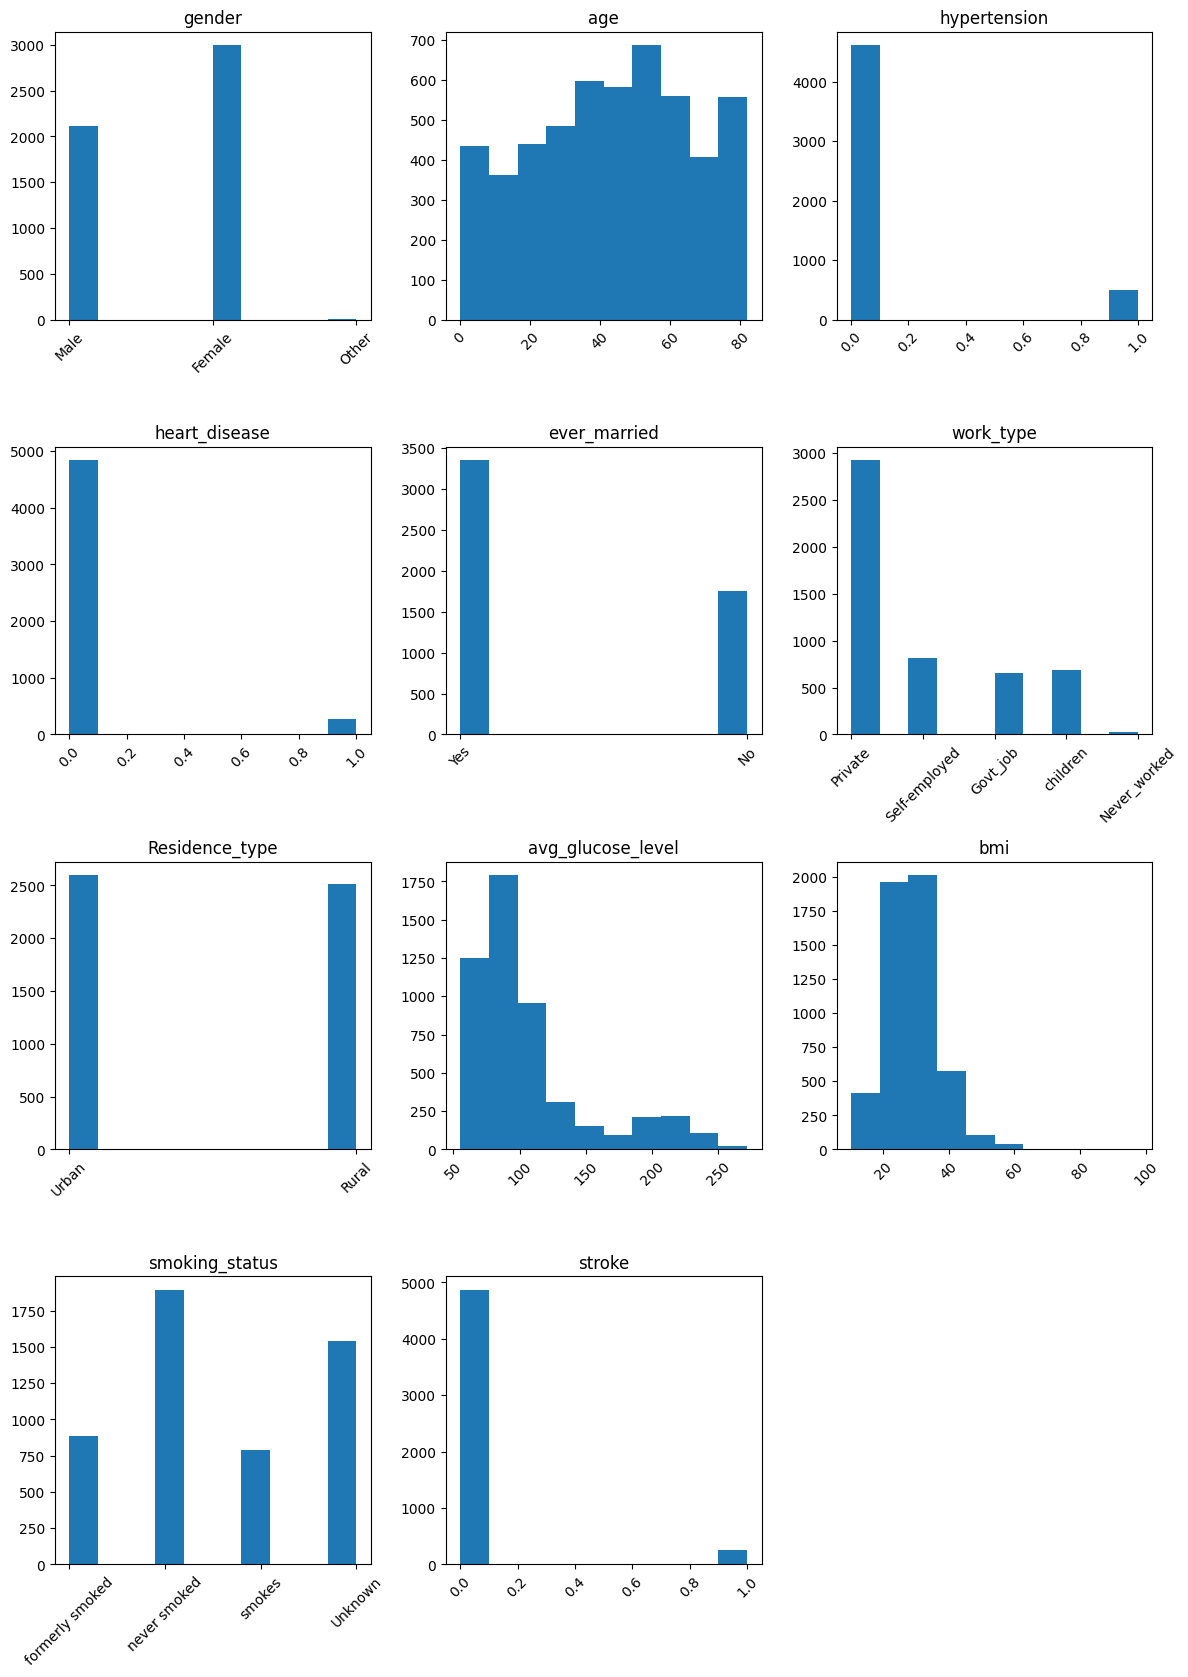

In [16]:
columns_list = list(df.columns)
plt.figure(figsize = (12,20))
for i in range(len(columns_list)):
    plt.subplot(5, 3, i + 1)
    plt.title(columns_list[i])
    plt.xticks(rotation = 45)
    plt.hist(df[columns_list[i]])

plt.tight_layout()

## Age

<Axes: xlabel='age'>

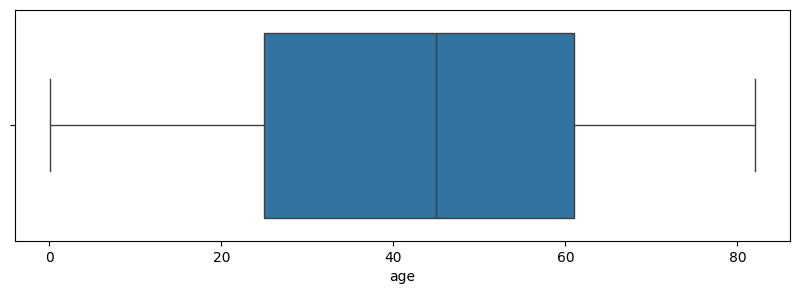

In [18]:
plt.figure(figsize = (10, 3))
sns.boxplot(x = 'age', data = df)

## Average Glucose Level

<Axes: xlabel='avg_glucose_level'>

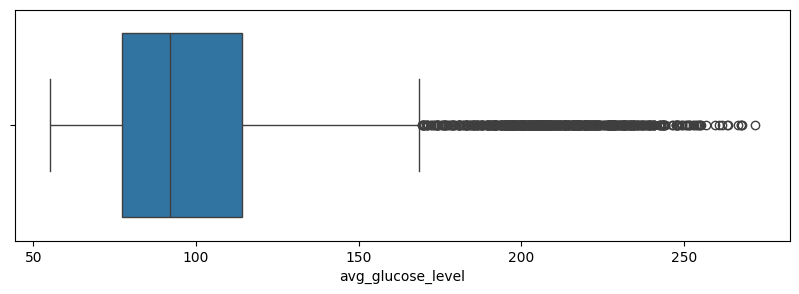

In [17]:
plt.figure(figsize = (10, 3))
sns.boxplot(x = 'avg_glucose_level', data = df)

## AVC Percent

([<matplotlib.patches.Wedge at 0x7bcb9c158590>,
 [Text(-1.0871361482645023, 0.16773489540528563, 'No Stroke'),
  Text(1.2847973307229401, -0.19823173047523968, 'Stroke')],
 [Text(-0.5929833535988194, 0.0914917611301558, '95.127%'),
  Text(0.790644511214117, -0.12198875721553208, '4.873%')])

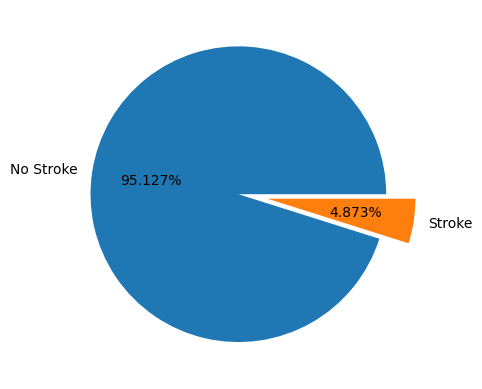

In [19]:
qtd_stroke = df['stroke'].value_counts()
plt.pie(qtd_stroke, labels = ['No Stroke','Stroke'], autopct='%.3f%%', explode = [0,0.2])

## Married

([<matplotlib.patches.Wedge at 0x7bcb9cad39d0>,
 [Text(-0.5182756139174329, 0.9702527444014307, 'Already Married'),
  Text(0.5324102528882477, -0.9967142632768292, 'Never Married')],
 [Text(-0.28269578940950885, 0.5292287696735076, '65.616%'),
  Text(0.29683049497309383, -0.5556902529773472, '34.384%')])

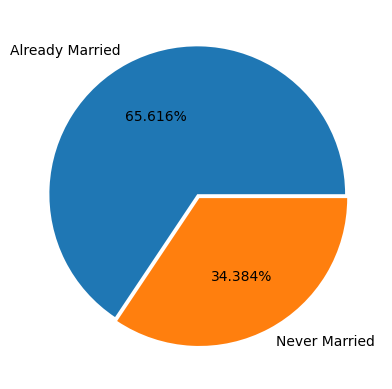

In [20]:
qtd_casado = df['ever_married'].value_counts()
plt.pie(qtd_casado, labels = ['Already Married', 'Never Married'], autopct = '%.3f%%', explode = [0,0.03])

## IDADE

/tmp/ipykernel_1841/450620810.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


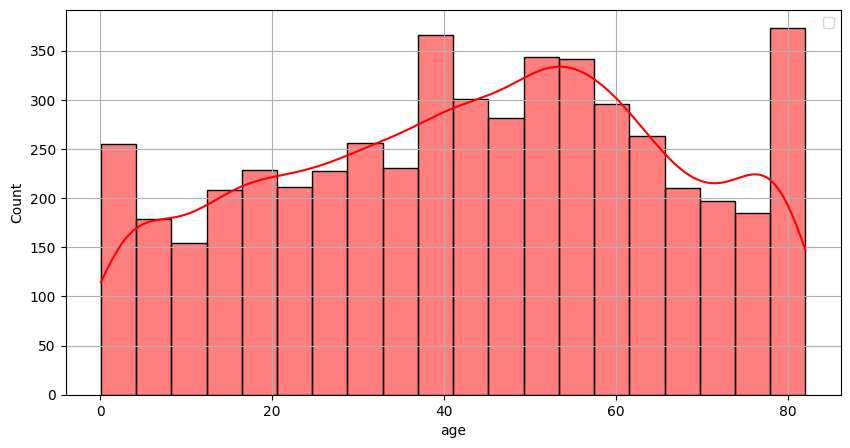

In [21]:
plt.figure(figsize=(10,5))
sns.histplot(df['age'], color = 'red', kde = True)
plt.legend()
plt.grid()

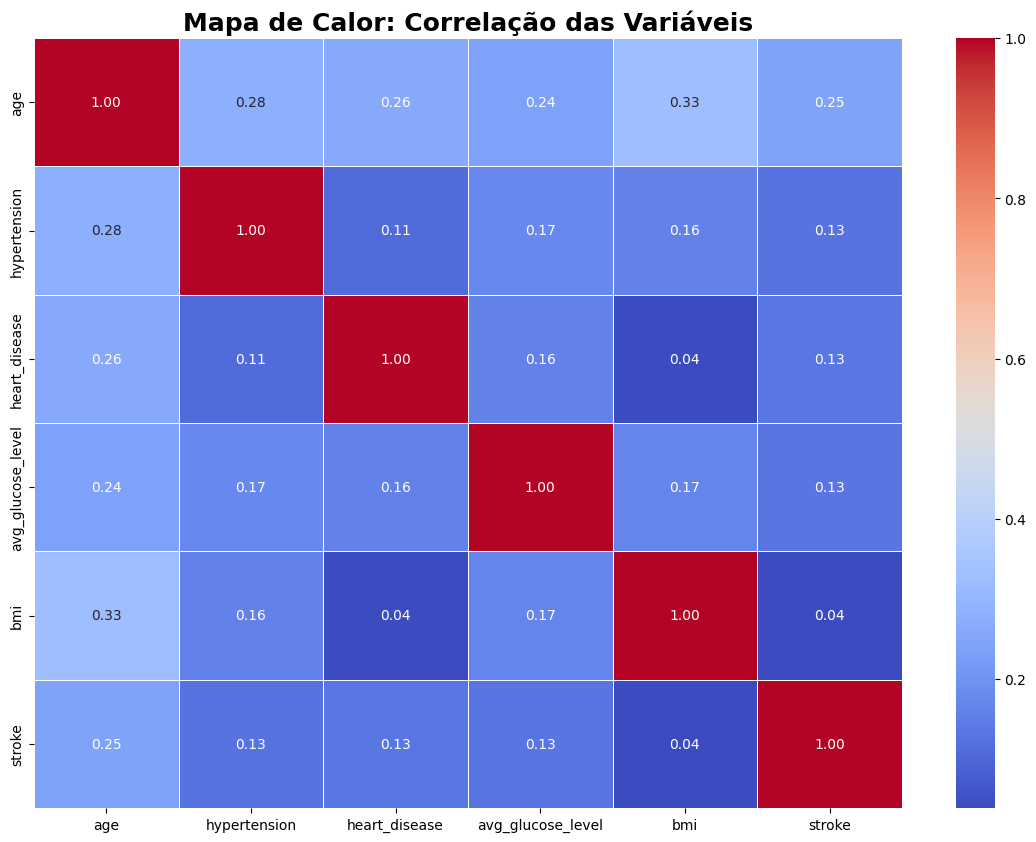

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ------------------------------------------------------------------
# HEATMAP DE CORRELAÇÃO (Corrigido para ignorar texto)
# ------------------------------------------------------------------
plt.figure(figsize=(14, 10))

# Passo 1: Filtra o DataFrame para pegar APENAS colunas com números (int, float) ou booleanos (True/False)
df_numerico = df.select_dtypes(include=['number', 'bool'])

# Passo 2: Calcula a correlação apenas nesse DataFrame numérico
sns.heatmap(df_numerico.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Mapa de Calor: Correlação das Variáveis', fontsize=18, fontweight='bold')
plt.show()

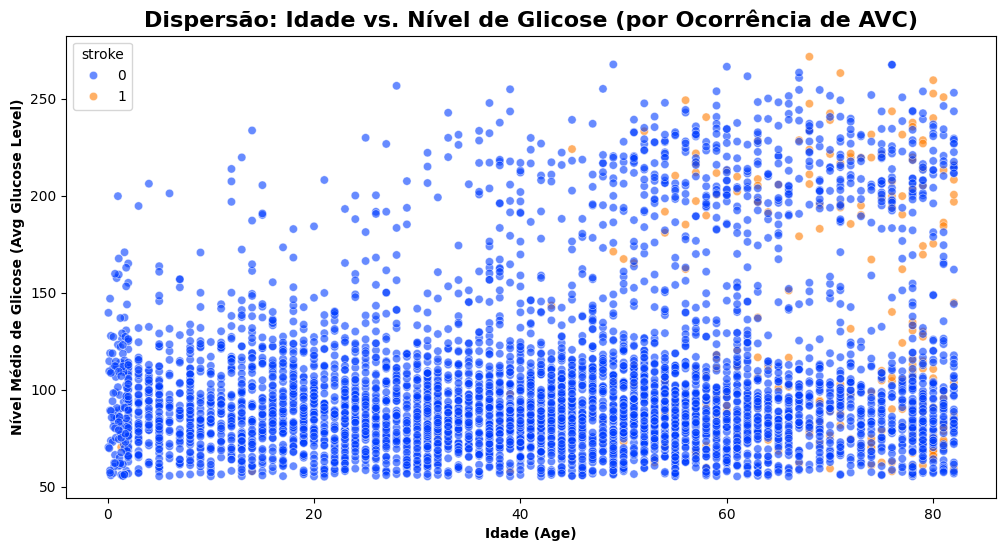

In [ ]:

plt.figure(figsize=(12, 6))

# x e y são as variáveis contínuas
# hue='stroke' pinta os pontos de cores diferentes se a pessoa teve AVC ou não
# alpha=0.6 deixa os pontos levemente transparentes para ver onde há sobreposição
sns.scatterplot(data=df, x='age', y='avg_glucose_level', hue='stroke', palette='bright', alpha=0.6)

plt.title('Dispersão: Idade vs. Nível de Glicose (por Ocorrência de AVC)', fontsize=16, fontweight='bold')
plt.xlabel('Idade (Age)', fontweight='bold')
plt.ylabel('Nível Médio de Glicose (Avg Glucose Level)', fontweight='bold')

plt.show()

# Convert Categorical Columns to Numeric

In [22]:
col_categ = df.select_dtypes(include = ['object']).columns.tolist()

In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                5110 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [24]:
print(col_categ)

['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']


In [25]:
df.head(5)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1


In [26]:
df = pd.get_dummies(df, columns=col_categ, drop_first=True)

In [27]:
df.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke,gender_Male,gender_Other,ever_married_Yes,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,Residence_type_Urban,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes
0,67.0,0,1,228.69,36.600000,1,True,False,True,False,True,False,False,True,True,False,False
1,61.0,0,0,202.21,28.893237,1,False,False,True,False,False,True,False,False,False,True,False
2,80.0,0,1,105.92,32.500000,1,True,False,True,False,True,False,False,False,False,True,False
3,49.0,0,0,171.23,34.400000,1,False,False,True,False,True,False,False,True,False,False,True
4,79.0,1,0,174.12,24.000000,1,False,False,True,False,False,True,False,False,False,True,False


# Comparing models

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix
)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE

In [29]:
from sklearn.linear_model import LogisticRegression
# 1. Divisão estratificada
X = df.drop('stroke', axis=1)
y = df['stroke']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Padronização (fit apenas no treino)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Técnicas de balanceamento
tecnicas = {
    '1. Sem Balanceamento': None,
    '2. Undersampling': RandomUnderSampler(random_state=42),
    '3. Oversampling': RandomOverSampler(random_state=42),
    '4. SMOTE': SMOTE(random_state=42)
}

REGRESSÃO LOGÍSTICA - 1. Sem Balanceamento
              precision    recall  f1-score   support

           0       0.95      1.00      0.98       972
           1       1.00      0.02      0.04        50

    accuracy                           0.95      1022
   macro avg       0.98      0.51      0.51      1022
weighted avg       0.95      0.95      0.93      1022



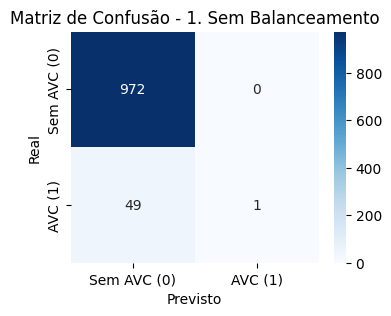

REGRESSÃO LOGÍSTICA - 2. Undersampling
              precision    recall  f1-score   support

           0       0.99      0.73      0.84       972
           1       0.14      0.82      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.78      0.54      1022
weighted avg       0.95      0.74      0.81      1022



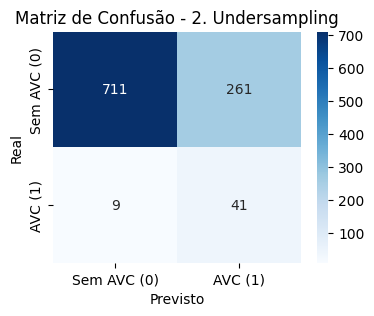

REGRESSÃO LOGÍSTICA - 3. Oversampling
              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.23        50

    accuracy                           0.74      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.74      0.82      1022



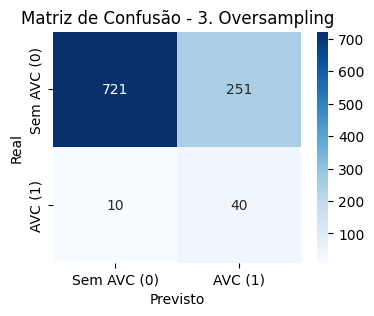

REGRESSÃO LOGÍSTICA - 4. SMOTE
              precision    recall  f1-score   support

           0       0.99      0.75      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



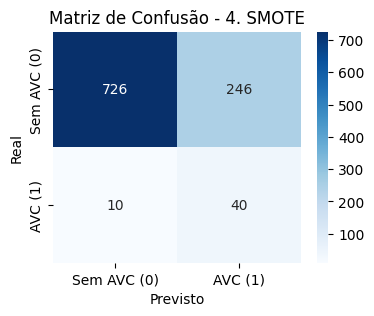

In [ ]:

modelos_treinados = {}

# 3. Treinamento, Classification Report e Matriz de Confusão
for nome_tec, sampler in tecnicas.items():
    if sampler is not None:
        X_res, y_res = sampler.fit_resample(X_train_scaled, y_train)
    else:
        X_res, y_res = X_train_scaled, y_train

    modelo = LogisticRegression(max_iter=1000, random_state=42)
    modelo.fit(X_res, y_res)
    modelos_treinados[nome_tec] = modelo

    y_pred = modelo.predict(X_test_scaled)

    print("=" * 60)
    print(f"REGRESSÃO LOGÍSTICA - {nome_tec}")
    print("=" * 60)
    print(classification_report(y_test, y_pred, zero_division=0))

    # Matriz de Confusão
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Sem AVC (0)', 'AVC (1)'],
                yticklabels=['Sem AVC (0)', 'AVC (1)'])
    plt.title(f'Matriz de Confusão - {nome_tec}')
    plt.xlabel('Previsto')
    plt.ylabel('Real')
    plt.show()

Como apenas 5% dos pacientes tiveram AVC e os perfis de idade/glicose de quem teve e quem não teve se sobrepõem muito, qualquer modelo honesto nesse conjunto de dados vai ficar com Precisão baixa (muitos falsos positivos) e F1-Score da classe 1 entre 0.25 e 0.35, mesmo com Recall alto (80%) e ROC-AUC bom (0.84).

Regressão Logística (SMOTE 25%) | Melhor Threshold: 0.55 | ROC-AUC: 0.8437
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       972
           1       0.32      0.44      0.37        50

    accuracy                           0.93      1022
   macro avg       0.64      0.70      0.67      1022
weighted avg       0.94      0.93      0.93      1022



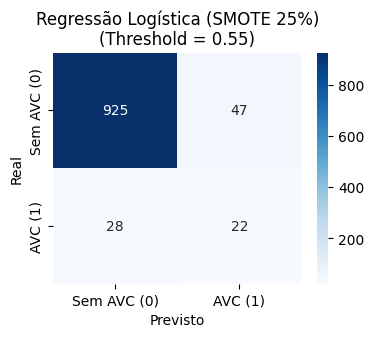

HistGradientBoosting (SMOTE 25%) | Melhor Threshold: 0.35 | ROC-AUC: 0.8327
              precision    recall  f1-score   support

           0       0.97      0.94      0.95       972
           1       0.24      0.40      0.30        50

    accuracy                           0.91      1022
   macro avg       0.60      0.67      0.63      1022
weighted avg       0.93      0.91      0.92      1022



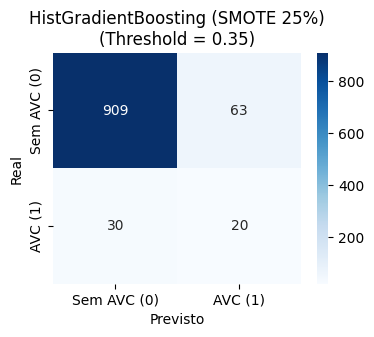

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import classification_report, confusion_matrix, f1_score, roc_auc_score
from imblearn.over_sampling import SMOTE

# 1. Feature Engineering rápida em cima do df atual
df_melhorado = df.copy()
df_melhorado['risco_cardio'] = df_melhorado['hypertension'] + df_melhorado['heart_disease']
df_melhorado['idade_x_glicose'] = df_melhorado['age'] * df_melhorado['avg_glucose_level']

X = df_melhorado.drop('stroke', axis=1)
y = df_melhorado['stroke']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Padronização
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. SMOTE suavizado (25% em vez de 100% para evitar enxurrada de falsos positivos)
smote_suave = SMOTE(sampling_strategy=0.25, random_state=42)
X_res, y_res = smote_suave.fit_resample(X_train_scaled, y_train)

# 3. Modelos para testar
modelos_teste = {
    'Regressão Logística (SMOTE 25%)': LogisticRegression(C=0.5, max_iter=1000, random_state=42),
    'HistGradientBoosting (SMOTE 25%)': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, random_state=42)
}

for nome, modelo in modelos_teste.items():
    modelo.fit(X_res, y_res)
    y_prob = modelo.predict_proba(X_test_scaled)[:, 1]

    # Busca o threshold que gera o melhor F1-Score para a classe 1 (AVC)
    thresholds = np.arange(0.15, 0.75, 0.05)
    melhor_t = 0.5
    melhor_f1 = 0
    for t in thresholds:
        f1 = f1_score(y_test, (y_prob >= t).astype(int), zero_division=0)
        if f1 > melhor_f1:
            melhor_f1 = f1
            melhor_t = t

    y_pred_otimizado = (y_prob >= melhor_t).astype(int)

    print("=" * 65)
    print(f"{nome} | Melhor Threshold: {melhor_t:.2f} | ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")
    print("=" * 65)
    print(classification_report(y_test, y_pred_otimizado, zero_division=0))

    cm = confusion_matrix(y_test, y_pred_otimizado)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Sem AVC (0)', 'AVC (1)'],
                yticklabels=['Sem AVC (0)', 'AVC (1)'])
    plt.title(f'{nome}\n(Threshold = {melhor_t:.2f})')
    plt.xlabel('Previsto')
    plt.ylabel('Real')
    plt.show()

In [30]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE

# 1. Prepara e treina o modelo usando o df original (evita conflito com X e scaler do df_melhorado)
X_orig = df.drop('stroke', axis=1)
y_orig = df['stroke']
colunas_modelo = X_orig.columns

X_train_orig, _, y_train_orig, _ = train_test_split(
    X_orig, y_orig, test_size=0.2, random_state=42, stratify=y_orig
)

scaler_final = StandardScaler()
X_train_scaled_orig = scaler_final.fit_transform(X_train_orig)

smote = SMOTE(random_state=42)
X_res_orig, y_res_orig = smote.fit_resample(X_train_scaled_orig, y_train_orig)

modelo_final = LogisticRegression(max_iter=1000, random_state=42)
modelo_final.fit(X_res_orig, y_res_orig)


def prever_avc():
    print("=== SIMULADOR DE RISCO DE AVC (Regressão Logística + SMOTE) ===")
    print("Preencha os campos abaixo:\n")

    # 1. Variáveis numéricas e binárias
    age = float(input("Idade (ex: 45): ").replace(',', '.').strip())
    hypertension = int(input("Possui hipertensão? (0 = Não, 1 = Sim): ").strip())
    heart_disease = int(input("Possui doença cardíaca? (0 = Não, 1 = Sim): ").strip())
    avg_glucose_level = float(input("Nível médio de glicose (ex: 95.5): ").replace(',', '.').strip())
    bmi = float(input("IMC / BMI (ex: 26.4): ").replace(',', '.').strip())

    # 2. Variáveis categóricas
    mapa_genero = {'1': 'Male', '2': 'Female', '3': 'Other'}
    gender = mapa_genero.get(
        input("Gênero (1 = Masculino, 2 = Feminino, 3 = Outro): ").strip(),
        'Female'
    )

    mapa_casado = {'1': 'Yes', '0': 'No'}
    ever_married = mapa_casado.get(
        input("Já foi casado(a)? (1 = Sim, 0 = Não): ").strip(),
        'No'
    )

    mapa_trabalho = {
        '1': 'Private', '2': 'Self-employed', '3': 'Govt_job',
        '4': 'children', '5': 'Never_worked'
    }
    work_type = mapa_trabalho.get(
        input("Trabalho (1 = Privado, 2 = Autônomo, 3 = Público, 4 = Criança, 5 = Nunca trabalhou): ").strip(),
        'Private'
    )

    mapa_residencia = {'1': 'Urban', '2': 'Rural'}
    Residence_type = mapa_residencia.get(
        input("Residência (1 = Urbana, 2 = Rural): ").strip(),
        'Urban'
    )

    mapa_fumo = {
        '1': 'never smoked', '2': 'formerly smoked',
        '3': 'smokes', '4': 'Unknown'
    }
    smoking_status = mapa_fumo.get(
        input("Tabagismo (1 = Nunca fumou, 2 = Ex-fumante, 3 = Fuma atualmente, 4 = Não informado): ").strip(),
        'never smoked'
    )

    # 3. Cria o DataFrame e alinha exatamente com as colunas usadas no treino
    novo_paciente = pd.DataFrame([{
        'gender': gender,
        'age': age,
        'hypertension': hypertension,
        'heart_disease': heart_disease,
        'ever_married': ever_married,
        'work_type': work_type,
        'Residence_type': Residence_type,
        'avg_glucose_level': avg_glucose_level,
        'bmi': bmi,
        'smoking_status': smoking_status
    }])

    novo_encoded = pd.get_dummies(novo_paciente, dtype=int)
    novo_alinhado = novo_encoded.reindex(columns=colunas_modelo, fill_value=0)

    # 4. Escalonamento e predição
    novo_escalonado = scaler_final.transform(novo_alinhado)
    pred = modelo_final.predict(novo_escalonado)[0]
    prob = modelo_final.predict_proba(novo_escalonado)[0][1] * 100

    resultado = "RISCO DE AVC (1)" if pred == 1 else "SEM RISCO APARENTE (0)"

    print("\n" + "=" * 50)
    print(f"RESULTADO: {resultado}")
    print(f"Probabilidade estimada: {prob:.1f}%")
    print("=" * 50)


# Chamada da função para abrir os inputs
prever_avc()

=== SIMULADOR DE RISCO DE AVC (Regressão Logística + SMOTE) ===
Preencha os campos abaixo:

Idade (ex: 45): 30
Possui hipertensão? (0 = Não, 1 = Sim): 0
Possui doença cardíaca? (0 = Não, 1 = Sim): 0
Nível médio de glicose (ex: 95.5): 90
IMC / BMI (ex: 26.4): 26
Gênero (1 = Masculino, 2 = Feminino, 3 = Outro): 2
Já foi casado(a)? (1 = Sim, 0 = Não): 1
Trabalho (1 = Privado, 2 = Autônomo, 3 = Público, 4 = Criança, 5 = Nunca trabalhou): 1
Residência (1 = Urbana, 2 = Rural): 1
Tabagismo (1 = Nunca fumou, 2 = Ex-fumante, 3 = Fuma atualmente, 4 = Não informado): 1

RESULTADO: SEM RISCO APARENTE (0)
Probabilidade estimada: 5.4%


In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Garante que X e y são do DataFrame original (desbalanceado)
X_cv = df.drop('stroke', axis=1)
y_cv = df['stroke']

print("Proporção atual de y_cv:\n", y_cv.value_counts(normalize=True), "\n")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

modelos_cv = {
    'Regressão Logística': LogisticRegression(C=0.5, max_iter=1000, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, random_state=42)
}

for nome, modelo in modelos_cv.items():
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(sampling_strategy='auto', random_state=42)),
        ('clf', modelo)
    ])

    scores = cross_validate(
        pipe, X_cv, y_cv,
        cv=cv,
        scoring=['roc_auc', 'recall', 'f1'],
        return_train_score=True
    )

    print(f"=== {nome} (5-Fold CV) ===")
    for metrica in ['roc_auc', 'recall', 'f1']:
        treino = scores[f'train_{metrica}'].mean()
        val = scores[f'test_{metrica}'].mean()
        diff = treino - val
        print(f"{metrica.upper():8s} | Treino: {treino:.4f} | Validação: {val:.4f} | Diferença: {diff:+.4f}")
    print()

Proporção atual de y_cv:
 stroke
0    0.951272
1    0.048728
Name: proportion, dtype: float64 

=== Regressão Logística (5-Fold CV) ===
ROC_AUC  | Treino: 0.8464 | Validação: 0.8354 | Diferença: +0.0110
RECALL   | Treino: 0.7962 | Validação: 0.7869 | Diferença: +0.0093
F1       | Treino: 0.2361 | Validação: 0.2329 | Diferença: +0.0032

=== HistGradientBoosting (5-Fold CV) ===
ROC_AUC  | Treino: 0.8861 | Validação: 0.8124 | Diferença: +0.0737
RECALL   | Treino: 0.7410 | Validação: 0.5699 | Diferença: +0.1711
F1       | Treino: 0.3039 | Validação: 0.2309 | Diferença: +0.0730

